# W3 · From separate charts to a visual system

Business Intelligence IIB423T-1 · Universidad del Desarrollo · Instructor: Tomás Fontecilla Correa
GROUP_01 · Members: Matías López, Cristóbal Ramírez · Workshop 3

This notebook is the editable source of the W3 report (`report/GROUP_01_W3_Report.docx` and `.pdf`). It draws the three before-and-after pairs from the **C2 results only**. It trains no model and adds no new analysis: every value comes from the tables that `GROUP_01_C2/notebooks/C2_model.ipynb` wrote.

The visual system guide (report section 2) is implemented in `w3_style.py`. All three final views import it, so colours, shapes, names, scales, text sizes and layout are shared by construction.

| Section | Content | Report section |
|---|---|---|
| 1 | Inputs and checksums | 5 (sources) |
| 2 | Value checks: every value shown agrees with C2 | 3 |
| 3 | View 1, before (C2 Figure 2) and after | 3.1 |
| 4 | View 2, before (C2 Figure 1) and after | 3.2 |
| 5 | View 3, before (C2 table) and after | 3.3 |
| 6 | Table of every value shown in the final views | 3 |
| 7 | Packaging check | README |

## 1. Inputs

The notebook reads five C2 tables and the two C2 figures used as earlier versions. It writes only inside `GROUP_01_W3/`.

In [1]:
import sys, platform, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import w3_style as S

BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # GROUP_01_W3/
REPO = BASE.parent
C2 = REPO / "GROUP_01_C2"
C2T, C2F = C2 / "data/processed", C2 / "data/figures"
OUT, FIG = BASE / "data/processed", BASE / "data/figures"
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
assert (C2T / "c2_08_summary.csv").exists(), "GROUP_01_C2/ must sit next to GROUP_01_W3/, as in the repository"
S.apply_rcparams()
pd.set_option("display.width", 160)
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| matplotlib", matplotlib.__version__, "|", platform.system())

def sha256(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()

INPUTS = ["c2_03_validation_threshold_curve.csv", "c2_04_validation_metrics.csv", "c2_05_test_metrics.csv",
          "c2_07_test_by_admission_type.csv", "c2_08_summary.csv"]
inputs = pd.DataFrame([{"file": f"GROUP_01_C2/data/processed/{f}", "bytes": (C2T/f).stat().st_size, "sha256": sha256(C2T/f)} for f in INPUTS]
                      + [{"file": f"GROUP_01_C2/data/figures/{f}", "bytes": (C2F/f).stat().st_size, "sha256": sha256(C2F/f)}
                         for f in ["c2_fig1_validation_threshold.png", "c2_fig2_test_confusion_matrices.png"]])
inputs.to_csv(OUT / "w3_00_inputs.csv", index=False)
inputs

Python 3.13.18 | pandas 3.0.5 | numpy 2.5.3 | matplotlib 3.11.2 | Linux


,file,bytes,sha256
0,GROUP_01_C2/data/processed/c2_03_validation_th...,5160,bab1d82da8417e6baef203b2ea5aa5dc40b3a780a0bc6c...
1,GROUP_01_C2/data/processed/c2_04_validation_me...,390,85f132c2eaa9727c15f94d59525cc443ad353423bf908d...
2,GROUP_01_C2/data/processed/c2_05_test_metrics.csv,301,5f190685efab8c45d8e4ec66e333d4e06b8c0d4bb3df78...
3,GROUP_01_C2/data/processed/c2_07_test_by_admis...,271,288ec5025a4fee01238f1658be3df9589aff429b93cf62...
4,GROUP_01_C2/data/processed/c2_08_summary.csv,365,3ab401d49ed5b4bdd4ad12118f1bf1f13e3f429bb5d7f5...
5,GROUP_01_C2/data/figures/c2_fig1_validation_th...,104607,dfc00b42650e65e0e87008922c280931f245437b3d54ad...
6,GROUP_01_C2/data/figures/c2_fig2_test_confusio...,104284,3fd94609a5d8e6eb28e947827daa03685f140e41740208...


## 2. Value checks

The final views recompute recall, precision and share flagged from the C2 counts. These checks stop the notebook if any recomputed value differs from the C2 tables or from the C2 summary.

In [2]:
curve = pd.read_csv(C2T / "c2_03_validation_threshold_curve.csv")
val = pd.read_csv(C2T / "c2_04_validation_metrics.csv").set_index("rule")
test = pd.read_csv(C2T / "c2_05_test_metrics.csv").set_index("rule")
seg = pd.read_csv(C2T / "c2_07_test_by_admission_type.csv").set_index("TIPO_INGRESO")
summ = pd.read_csv(C2T / "c2_08_summary.csv", index_col=0)["value"]

TM, TB = test.loc["model, threshold 0.60"], test.loc["baseline: flag every emergency admission"]
VM, VB = val.loc["model, threshold 0.60 (chosen)"], val.loc["baseline: flag every emergency admission"]
VD = val.loc["model, default threshold 0.5"]
N_TEST = int(TM[["TP", "FP", "FN", "TN"]].sum())
N_VAL = int(VM[["TP", "FP", "FN", "TN"]].sum())
POS_TEST = int(TM.TP + TM.FN)
POS_VAL = int(VM.TP + VM.FN)

# Value checks: every number shown in the final views must agree with the C2 results.
checks = []
def check(name, ok):
    checks.append({"check": name, "passed": bool(ok)}); assert ok, name
check("test stays = C2 summary (655,093)", N_TEST == int(float(summ["test stays with label"])))
check("same test stays for model and rule", N_TEST == int(TB[["TP", "FP", "FN", "TN"]].sum()))
check("validation stays = C2 summary (214,565)", N_VAL == int(float(summ["validation stays with label"])))
for r, name in [(TM, "model"), (TB, "rule")]:
    check(f"test recall of {name} recomputed from counts", abs(r.TP/(r.TP+r.FN) - r.recall) < 5e-5)
    check(f"test precision of {name} recomputed from counts", abs(r.TP/(r.TP+r.FP) - r.precision) < 5e-5)
    check(f"test flagged % of {name} recomputed from counts", abs((r.TP+r.FP)/N_TEST*100 - r["flagged %"]) < 5e-3)
check("test prevalence = C2 summary (6.12%)", round(POS_TEST/N_TEST*100, 2) == float(summ["test prevalence %"]))
row60 = curve.loc[np.isclose(curve.threshold, 0.60)].iloc[0]
row50 = curve.loc[np.isclose(curve.threshold, 0.50)].iloc[0]
check("curve at 0.60 = validation table (chosen)", abs(row60.recall - VM.recall) < 5e-5 and abs(row60["flagged %"] - VM["flagged %"]) < 5e-3)
check("curve at 0.50 = validation table (default)", abs(row50.recall - VD.recall) < 5e-5 and abs(row50["flagged %"] - VD["flagged %"]) < 5e-3)
check("chosen threshold = C2 summary (0.6)", float(summ["threshold (from validation)"]) == 0.6)
check("admission types add up to the test stays", int(seg.stays.sum()) == N_TEST)
ext_by_type = seg.stays * seg["prevalence %"] / 100
check("extreme stays by type add up to the test total (rounding of C2 table, +-10)", abs(ext_by_type.sum() - POS_TEST) <= 10)
check("emergency rule catches every extreme emergency stay (recall 1.0 in C2 table)", seg.loc["URGENCIA", "baseline recall"] == 1.0)
check("extreme emergency stays = rule true positives (rounding, +-5)", abs(ext_by_type["URGENCIA"] - TB.TP) <= 5)
checks = pd.DataFrame(checks); checks.to_csv(OUT / "w3_01_value_checks.csv", index=False)
print(f"{checks.passed.sum()} of {len(checks)} value checks passed")
checks

17 of 17 value checks passed


,check,passed
0,"test stays = C2 summary (655,093)",True
1,same test stays for model and rule,True
2,"validation stays = C2 summary (214,565)",True
3,test recall of model recomputed from counts,True
4,test precision of model recomputed from counts,True
5,test flagged % of model recomputed from counts,True
6,test recall of rule recomputed from counts,True
7,test precision of rule recomputed from counts,True
8,test flagged % of rule recomputed from counts,True
9,test prevalence = C2 summary (6.12%),True


## 3. View 1: model alert vs emergency rule on the test set

**Question.** On 2024 admissions, does the model alert catch extreme stays more efficiently than flagging every emergency admission?
**Task.** *Compare* the two rules on three attributes: extreme stays caught, admissions flagged and flags that are extreme stays.

**Earlier version** (C2 Figure 2, unchanged): two confusion matrices with the same eight test counts.

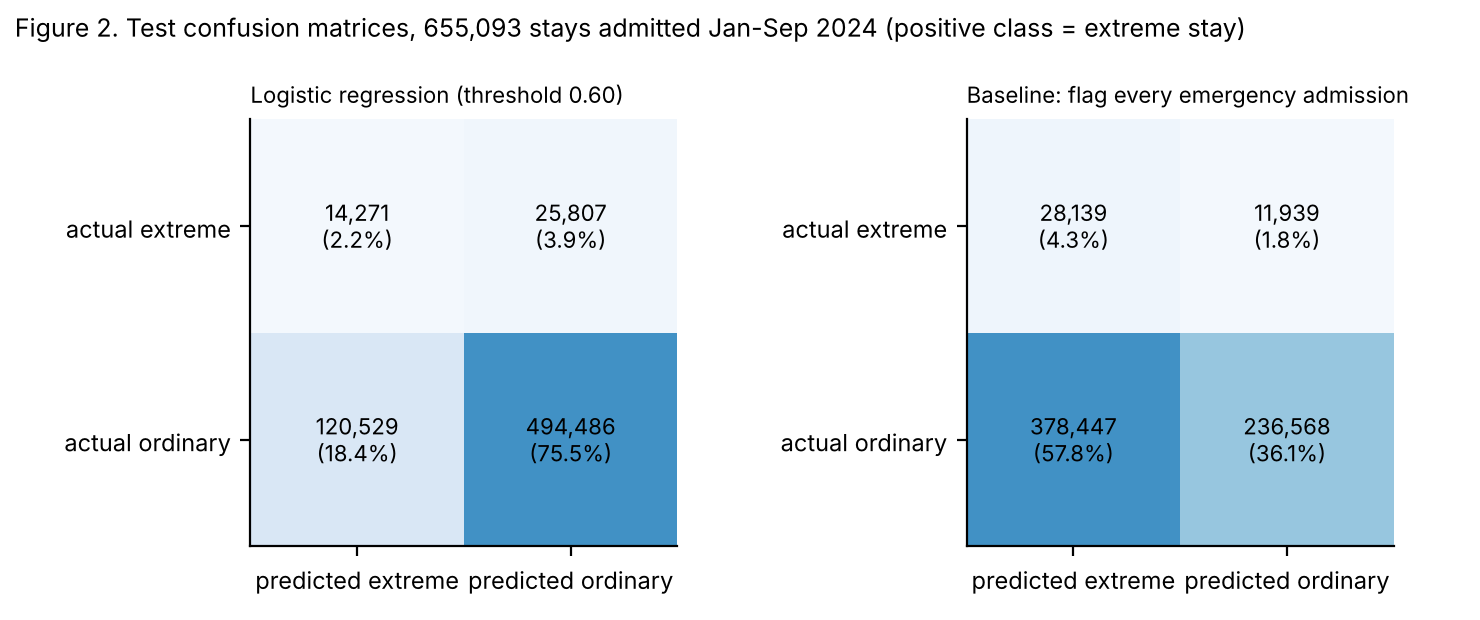

In [3]:
from IPython.display import Image, display
display(Image(filename=str(C2F / "c2_fig2_test_confusion_matrices.png"), width=760))

**Improved version.** The same eight counts, turned into the three measures the committee compares, on aligned bars with a shared 0-100% scale (panels 1-2) and a 0-20% scale with the base rate (panel 3).

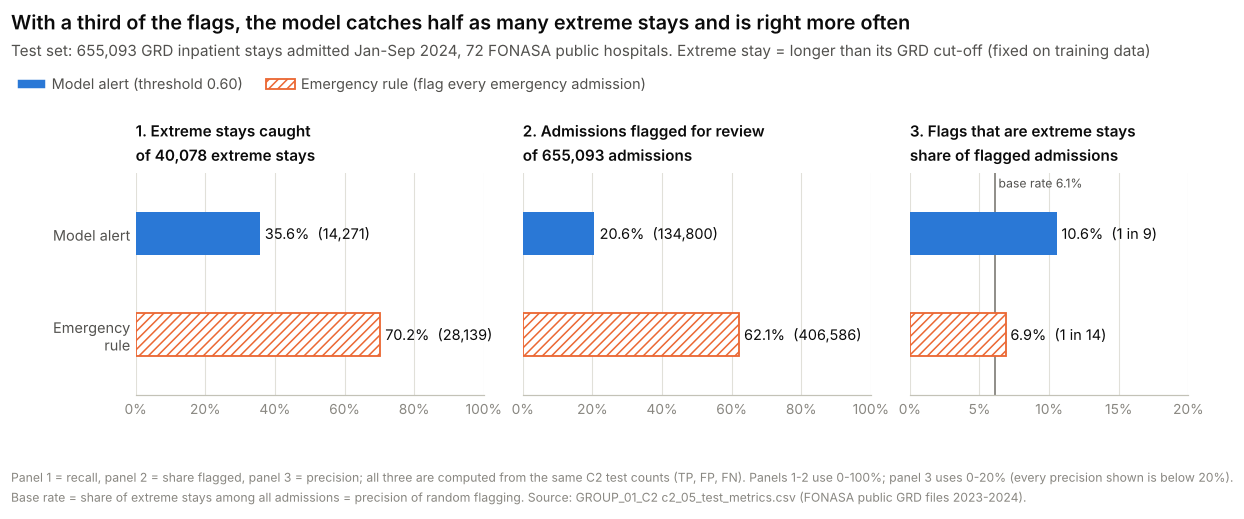

In [4]:
def v1_figure():
    rows = [("model", TM, S.MODEL), ("rule", TB, S.RULE)]
    caught = {k: r.TP / POS_TEST * 100 for k, r, _ in rows}
    flagged = {k: (r.TP + r.FP) / N_TEST * 100 for k, r, _ in rows}
    hit = {k: r.TP / (r.TP + r.FP) * 100 for k, r, _ in rows}
    base_rate = POS_TEST / N_TEST * 100
    fig, axes = plt.subplots(1, 3, figsize=(11, 4.7), gridspec_kw=dict(width_ratios=[1, 1, 0.8], wspace=S.PANEL_GAP))
    fig.subplots_adjust(left=0.115, right=0.985, top=0.66, bottom=0.23)
    ypos = {"model": 1, "rule": 0}
    panels = [
        (axes[0], caught, S.SCALE_SHARE, f"1. Extreme stays caught\nof {S.num(POS_TEST)} extreme stays",
         lambda k, r: f"{S.pct(caught[k])}  ({S.num(r.TP)})"),
        (axes[1], flagged, S.SCALE_SHARE, f"2. Admissions flagged for review\nof {S.num(N_TEST)} admissions",
         lambda k, r: f"{S.pct(flagged[k])}  ({S.num(r.TP + r.FP)})"),
        (axes[2], hit, S.SCALE_PRECISION, "3. Flags that are extreme stays\nshare of flagged admissions",
         lambda k, r: f"{S.pct(hit[k])}  (1 in {(r.TP + r.FP) / r.TP:.0f})"),
    ]
    for ax, vals, lim, title, lab in panels:
        for k, r, col in rows:
            if k == "model":
                ax.barh(ypos[k], vals[k], height=0.42, color=col, edgecolor=S.SURFACE, linewidth=0)
            else:
                ax.barh(ypos[k], vals[k], height=0.42, color=S.SURFACE, edgecolor=col, hatch=S.RULE_HATCH, linewidth=1.2)
            ax.text(vals[k] + (lim[1] - lim[0]) * 0.015, ypos[k], lab(k, r), va="center", fontsize=S.SIZE_LABEL, color=S.INK)
        S.percent_axis(ax, lim, "x")
        ax.set_ylim(-0.6, 1.6); ax.set_yticks([1, 0]); ax.set_title(title, fontsize=S.SIZE_PANEL, linespacing=1.3)
        ax.spines["bottom"].set_visible(True)
        if ax is axes[0]:
            ax.set_yticklabels(["Model alert", "Emergency\nrule"])
        else:
            ax.set_yticklabels([])
    axes[2].axvline(base_rate, color=S.REFERENCE, lw=1.2, zorder=0)
    axes[2].text(base_rate, 1.5, f" base rate {S.pct(base_rate)}", fontsize=S.SIZE_NOTE, color=S.INK2, va="center")
    S.frame(fig,
            "With a third of the flags, the model catches half as many extreme stays and is right more often",
            f"Test set: {S.num(N_TEST)} GRD inpatient stays admitted Jan-Sep 2024, 72 FONASA public hospitals. Extreme stay = longer than its GRD cut-off (fixed on training data)",
            "Panel 1 = recall, panel 2 = share flagged, panel 3 = precision; all three are computed from the same C2 test counts (TP, FP, FN). Panels 1-2 use 0-100%; panel 3 uses 0-20% (every precision shown is below 20%).\n"
            "Base rate = share of extreme stays among all admissions = precision of random flagging. Source: GROUP_01_C2 c2_05_test_metrics.csv (FONASA public GRD files 2023-2024).",
            legend_items=S.bar_legend_items())
    return fig, dict(caught=caught, flagged=flagged, hit=hit, base_rate=base_rate)

fig1, v1 = v1_figure(); fig1.savefig(FIG / "w3_fig1_after_rules_compared.png"); plt.show()

## 4. View 2: the workload-coverage trade-off on the validation set

**Question.** How much review workload buys how much coverage, and where does the chosen threshold sit?
**Tasks.** *Locate* the chosen threshold 0.60; *summarize* the trade-off across all thresholds; *compare* it with the emergency rule and with random flagging.

**Earlier version** (C2 Figure 1, unchanged): precision, recall and F1 against the threshold.

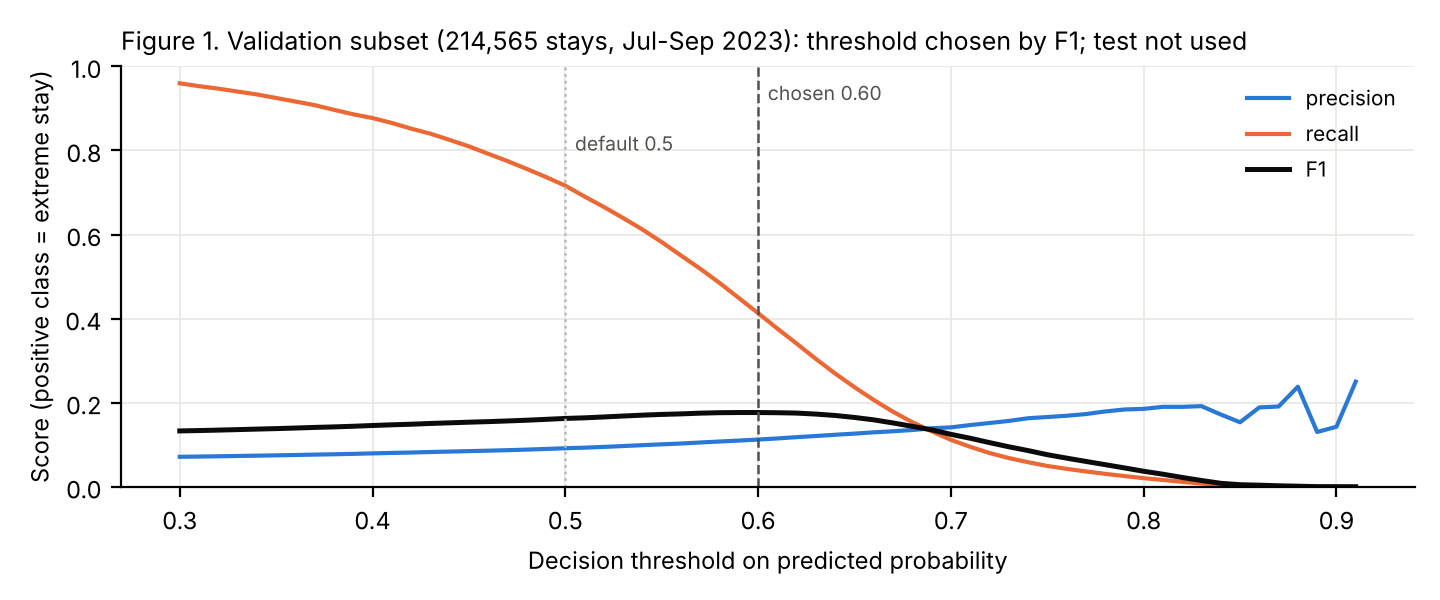

In [5]:
display(Image(filename=str(C2F / "c2_fig1_validation_threshold.png"), width=760))

**Improved version.** The same 62 rows of `c2_03` (thresholds 0.30 to 0.91) and the same validation rule row of `c2_04`, drawn as share caught against share flagged.

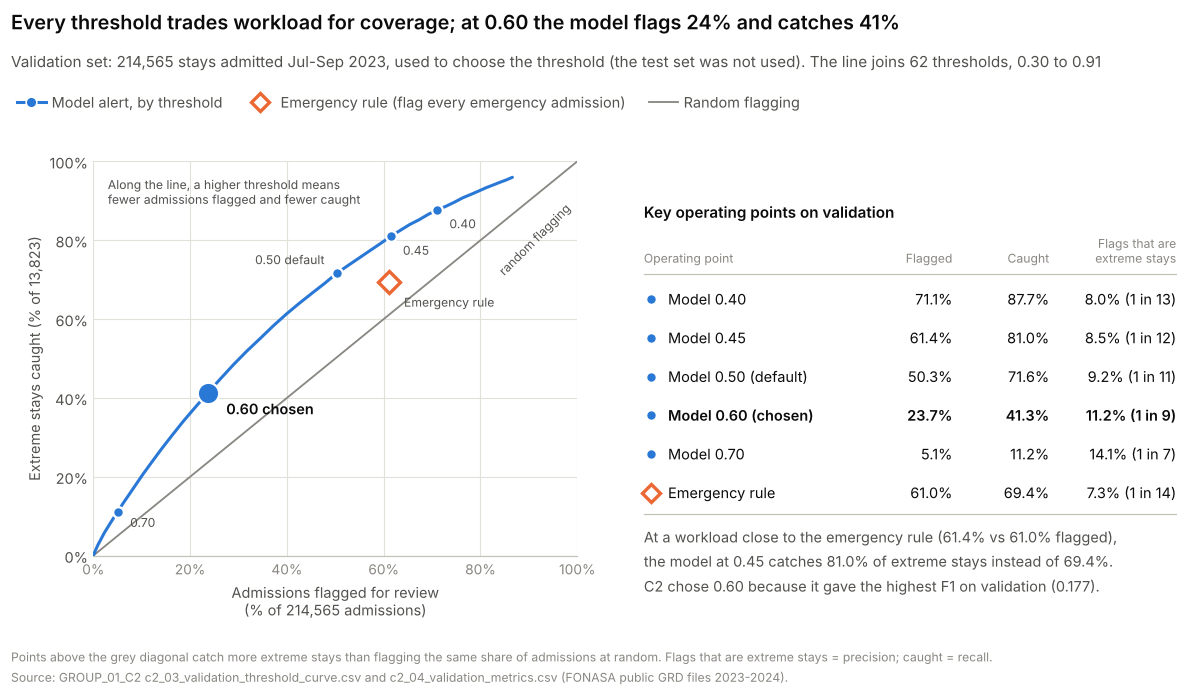

In [6]:
def v2_figure():
    c = curve.assign(flag=curve["flagged %"], caught=curve.recall * 100)
    at = lambda t: c.loc[np.isclose(c.threshold, t)].iloc[0]
    fig = plt.figure(figsize=(11, 6.4))
    ax = fig.add_axes([0.08, 0.20, 0.40, 0.56])
    ax.plot([0, 100], [0, 100], color=S.REFERENCE, lw=1.2, zorder=1)
    ax.text(97, 90, "random flagging", fontsize=S.SIZE_NOTE, color=S.INK2, ha="right", va="top", rotation=45, rotation_mode="anchor")
    ax.plot(c.flag, c.caught, color=S.MODEL, lw=2, zorder=2, solid_capstyle="round")
    for t, lab, off, ha in [(0.40, "0.40", (8, -12), "left"), (0.45, "0.45", (8, -12), "left"),
                            (0.50, "0.50 default", (-8, 6), "right"), (0.70, "0.70", (8, -10), "left")]:
        r = at(t)
        ax.plot(r.flag, r.caught, linestyle="none", zorder=3, **{**S.MODEL_MARKER, "markersize": 7})
        ax.annotate(lab, (r.flag, r.caught), xytext=off, textcoords="offset points", ha=ha, fontsize=S.SIZE_NOTE, color=S.INK2)
    r = at(0.60)
    ax.plot(r.flag, r.caught, linestyle="none", zorder=4, **{**S.MODEL_MARKER, "markersize": 14})
    ax.annotate("0.60 chosen", (r.flag, r.caught), xytext=(12, -14), textcoords="offset points",
                fontsize=S.SIZE_LABEL, color=S.INK, fontweight="semibold")
    b_flag, b_caught = VB["flagged %"], VB.recall * 100
    ax.plot(b_flag, b_caught, linestyle="none", zorder=4, **{**S.RULE_MARKER, "markersize": 10})
    ax.annotate("Emergency rule", (b_flag, b_caught), xytext=(10, -16), textcoords="offset points", fontsize=S.SIZE_NOTE, color=S.INK2)
    ax.text(3, 96, "Along the line, a higher threshold means\nfewer admissions flagged and fewer caught", fontsize=S.SIZE_NOTE,
            color=S.INK2, va="top")
    S.percent_axis(ax, S.SCALE_SHARE, "x"); S.percent_axis(ax, S.SCALE_SHARE, "y")
    ax.grid(axis="both", visible=True); ax.spines["bottom"].set_visible(True)
    ax.set_xlabel(f"Admissions flagged for review\n(% of {S.num(N_VAL)} admissions)")
    ax.set_ylabel(f"Extreme stays caught (% of {S.num(POS_VAL)})")

    # side table: the operating points the committee would discuss
    x0, y0, dy = 0.535, 0.60, 0.055
    cols = [(0.535, "Operating point", "left"), (0.79, "Flagged", "right"), (0.87, "Caught", "right"), (0.975, "Flags that are\nextreme stays", "right")]
    fig.text(0.535, 0.68, "Key operating points on validation", fontsize=S.SIZE_PANEL, fontweight="semibold", color=S.INK)
    for x, h, ha in cols:
        fig.text(x, y0 + 0.012, h, fontsize=S.SIZE_NOTE, color=S.MUTED, ha=ha, va="bottom")
    fig.add_artist(Line2D([0.535, 0.975], [y0, y0], transform=fig.transFigure, color=S.AXIS, lw=0.8))
    rows = [("Model 0.40", at(0.40), False), ("Model 0.45", at(0.45), False),
            ("Model 0.50 (default)", at(0.50), False), ("Model 0.60 (chosen)", at(0.60), True),
            ("Model 0.70", at(0.70), False)]
    table = []
    for i, (name, rr, bold) in enumerate(rows):
        table.append((name, rr.flag, rr.caught, rr.precision * 100))
    table.append(("Emergency rule", b_flag, b_caught, VB.precision * 100))
    for i, (name, f, cg, pr) in enumerate(table):
        y = y0 - dy * (i + 0.65)
        w = "semibold" if "chosen" in name else "normal"
        marker = S.RULE_MARKER if name == "Emergency rule" else {**S.MODEL_MARKER, "markersize": 7}
        fig.add_artist(Line2D([x0 + 0.006], [y], transform=fig.transFigure, linestyle="none", **marker))
        fig.text(x0 + 0.02, y, name, fontsize=S.SIZE_LABEL, color=S.INK, va="center", fontweight=w)
        fig.text(0.79, y, S.pct(f), fontsize=S.SIZE_LABEL, color=S.INK, va="center", ha="right", fontweight=w)
        fig.text(0.87, y, S.pct(cg), fontsize=S.SIZE_LABEL, color=S.INK, va="center", ha="right", fontweight=w)
        fig.text(0.975, y, f"{S.pct(pr)} (1 in {100/pr:.0f})", fontsize=S.SIZE_LABEL, color=S.INK, va="center", ha="right", fontweight=w)
    fig.add_artist(Line2D([0.535, 0.975], [y0 - dy * 6.2, y0 - dy * 6.2], transform=fig.transFigure, color=S.AXIS, lw=0.8))
    r45 = at(0.45)
    fig.text(0.535, y0 - dy * 6.5,
             f"At a workload close to the emergency rule ({S.pct(r45.flag)} vs {S.pct(b_flag)} flagged),\n"
             f"the model at 0.45 catches {S.pct(r45.caught)} of extreme stays instead of {S.pct(b_caught)}.\n"
             f"C2 chose 0.60 because it gave the highest F1 on validation ({r.F1:.3f}).",
             fontsize=S.SIZE_LABEL, color=S.INK2, va="top", linespacing=1.4)
    S.frame(fig,
            "Every threshold trades workload for coverage; at 0.60 the model flags 24% and catches 41%",
            f"Validation set: {S.num(N_VAL)} stays admitted Jul-Sep 2023, used to choose the threshold (the test set was not used). The line joins 62 thresholds, 0.30 to 0.91",
            "Points above the grey diagonal catch more extreme stays than flagging the same share of admissions at random. "
            "Flags that are extreme stays = precision; caught = recall.\n"
            "Source: GROUP_01_C2 c2_03_validation_threshold_curve.csv and c2_04_validation_metrics.csv (FONASA public GRD files 2023-2024).",
            legend_items=[Line2D([], [], color=S.MODEL, lw=2, label="Model alert, by threshold", marker="o", markersize=7,
                                 markerfacecolor=S.MODEL, markeredgecolor=S.SURFACE),
                          Line2D([], [], linestyle="none", label=S.NAME_RULE, **S.RULE_MARKER),
                          Line2D([], [], color=S.REFERENCE, lw=1.2, label="Random flagging")])
    return fig, dict(points=pd.DataFrame(table, columns=["operating point", "flagged %", "caught %", "precision %"]))

fig2, v2 = v2_figure(); fig2.savefig(FIG / "w3_fig2_after_threshold_tradeoff.png"); plt.show()

## 5. View 3: where the model alert works, by admission type (test set)

**Question.** For which admission types does the alert work, and where does it miss most extreme stays?
**Tasks.** *Compare* caught and precision across admission types; *identify* the type where the alert misses most.

**Earlier version**: the C2 notebook showed this result only as a printed table (section 6, `seg.round(3)`, saved as `c2_07`). It is reproduced here exactly as printed.

In [7]:
def v3_before():
    """Earlier version: the admission-type table exactly as the C2 notebook printed it (section 6, seg.round(3))."""
    printed = seg.round(3).to_string()
    fig = plt.figure(figsize=(8.6, 1.7))
    fig.text(0.01, 0.5, printed, family="DejaVu Sans Mono", fontsize=9.5, va="center", ha="left", color="#000000")
    fig.savefig(FIG / "w3_fig3_before_c2_table.png", dpi=200)
    return fig, printed
fig3b, printed = v3_before(); print(printed); plt.show()

                 stays  prevalence %  model recall  model precision  baseline recall  baseline precision
TIPO_INGRESO                                                                                            
URGENCIA      406586.0         6.921         0.410            0.103              1.0               0.069
PROGRAMADA    137887.0         3.126         0.029            0.088              0.0               0.000
OBSTETRICA    110586.0         6.898         0.340            0.122              0.0               0.000
DESCONOCIDO       34.0         2.941         0.000            0.000              0.0               0.000


<Figure size 946x187 with 0 Axes>

**Improved version.** The same `c2_07` values, in two panels with the shared names, units, colours and shapes of the system.

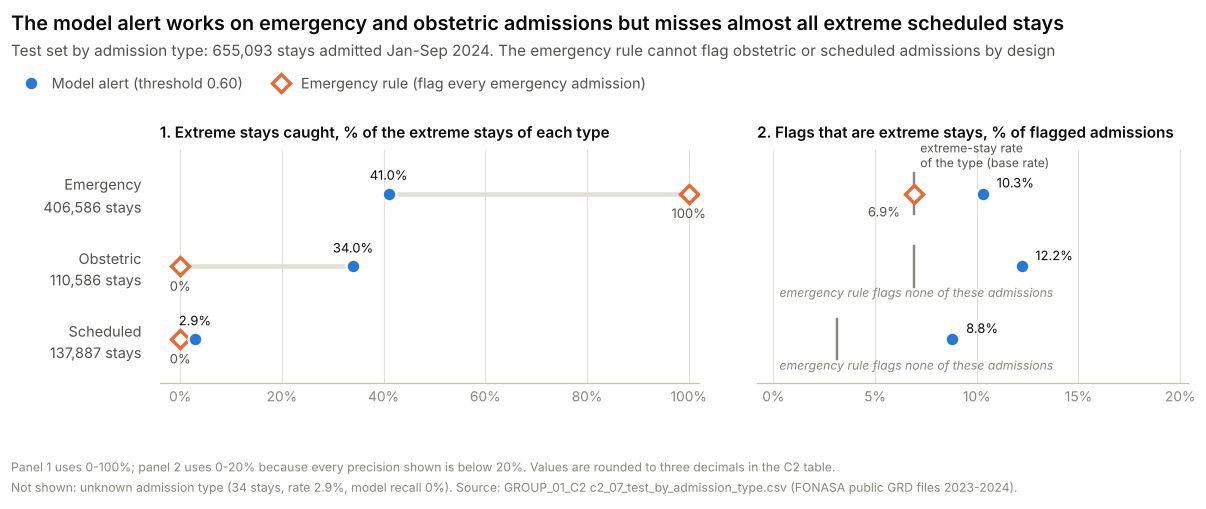

In [8]:
def v3_figure():
    order = ["URGENCIA", "OBSTETRICA", "PROGRAMADA"]   # largest share caught first
    d = seg.loc[order].copy()
    d["rate"] = d["prevalence %"]
    y = {k: i for i, k in enumerate(reversed(order))}
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw=dict(width_ratios=[1.25, 1], wspace=S.PANEL_GAP))
    fig.subplots_adjust(left=0.135, right=0.985, top=0.70, bottom=0.24)
    a, b = axes
    for k in order:
        r = d.loc[k]
        a.plot([r["model recall"] * 100, r["baseline recall"] * 100], [y[k], y[k]], color=S.GRID, lw=3, zorder=1, solid_capstyle="round")
        a.plot(r["baseline recall"] * 100, y[k], linestyle="none", zorder=3, **S.RULE_MARKER)
        a.plot(r["model recall"] * 100, y[k], linestyle="none", zorder=4, **S.MODEL_MARKER)
        a.annotate(S.pct(r["model recall"] * 100), (r["model recall"] * 100, y[k]), xytext=(0, 9), textcoords="offset points",
                   ha="center", fontsize=S.SIZE_NOTE + 0.5, color=S.INK)
        a.annotate(S.pct(r["baseline recall"] * 100, 0), (r["baseline recall"] * 100, y[k]), xytext=(0, -16), textcoords="offset points",
                   ha="center", fontsize=S.SIZE_NOTE + 0.5, color=S.INK2)
        # precision panel
        b.plot([r.rate, r.rate], [y[k] - 0.28, y[k] + 0.28], color=S.REFERENCE, lw=1.6, zorder=1)
        b.plot(r["model precision"] * 100, y[k], linestyle="none", zorder=4, **S.MODEL_MARKER)
        b.annotate(S.pct(r["model precision"] * 100), (r["model precision"] * 100, y[k]), xytext=(9, 4), textcoords="offset points",
                   fontsize=S.SIZE_NOTE + 0.5, color=S.INK)
        if r["baseline recall"] > 0:
            b.plot(r["baseline precision"] * 100, y[k], linestyle="none", zorder=3, **S.RULE_MARKER)
            b.annotate(S.pct(r["baseline precision"] * 100), (r["baseline precision"] * 100, y[k]), xytext=(-9, -15), textcoords="offset points",
                       ha="right", fontsize=S.SIZE_NOTE + 0.5, color=S.INK2)
        else:
            b.text(0.3, y[k] - 0.36, "emergency rule flags none of these admissions", fontsize=S.SIZE_NOTE, color=S.MUTED, va="center", style="italic")
    top = y["URGENCIA"]
    b.annotate("extreme-stay rate\nof the type (base rate)", (d.loc["URGENCIA", "rate"], top + 0.28), xytext=(4, 2),
               textcoords="offset points", fontsize=S.SIZE_NOTE, color=S.INK2, va="bottom")
    labels = [f"{S.ADMISSION_TYPE_EN[k]}\n{S.num(d.loc[k, 'stays'])} stays" for k in reversed(order)]
    for ax, lim, title in [(a, S.SCALE_SHARE, "1. Extreme stays caught, % of the extreme stays of each type"),
                           (b, S.SCALE_PRECISION, "2. Flags that are extreme stays, % of flagged admissions")]:
        S.percent_axis(ax, lim, "x"); ax.set_xlim(lim[0] - (lim[1] - lim[0]) * 0.04, lim[1] + (lim[1] - lim[0]) * 0.02)
        ax.set_ylim(-0.6, len(order) - 0.4); ax.set_yticks(range(len(order))); ax.tick_params(axis="y", pad=12)
        ax.set_title(title, fontsize=S.SIZE_PANEL); ax.spines["bottom"].set_visible(True)
    a.set_yticklabels(labels, linespacing=1.3); b.set_yticklabels([])
    unk = seg.loc["DESCONOCIDO"]
    S.frame(fig,
            "The model alert works on emergency and obstetric admissions but misses almost all extreme scheduled stays",
            f"Test set by admission type: {S.num(N_TEST)} stays admitted Jan-Sep 2024. The emergency rule cannot flag obstetric or scheduled admissions by design",
            f"Panel 1 uses 0-100%; panel 2 uses 0-20% because every precision shown is below 20%. Values are rounded to three decimals in the C2 table. "
            f"\nNot shown: unknown admission type ({S.num(unk.stays)} stays, rate {S.pct(unk['prevalence %'])}, model recall {unk['model recall']:.0%}). "
            "Source: GROUP_01_C2 c2_07_test_by_admission_type.csv (FONASA public GRD files 2023-2024).")
    return fig, d

fig3, v3 = v3_figure(); fig3.savefig(FIG / "w3_fig3_after_admission_type.png"); plt.show()

## 6. Every value shown in the final views

One row per number printed in a final view, rounded as displayed. Use it to check the report text against the figures.

In [9]:
shown = []
for k, lab in [("model", S.NAME_MODEL), ("rule", S.NAME_RULE)]:
    shown += [("View 1 (test)", lab, "extreme stays caught %", round(v1["caught"][k], 1)),
              ("View 1 (test)", lab, "admissions flagged %", round(v1["flagged"][k], 1)),
              ("View 1 (test)", lab, "flags that are extreme stays %", round(v1["hit"][k], 1))]
shown.append(("View 1 (test)", "all admissions", "base rate %", round(v1["base_rate"], 1)))
for _, r in v2["points"].iterrows():
    for col in ["flagged %", "caught %", "precision %"]:
        shown.append(("View 2 (validation)", r["operating point"], {"flagged %": "admissions flagged %", "caught %": "extreme stays caught %", "precision %": "flags that are extreme stays %"}[col], round(r[col], 1)))
for k, r in v3.iterrows():
    t = S.ADMISSION_TYPE_EN[k]
    shown += [("View 3 (test)", f"{t}: model", "extreme stays caught %", round(r["model recall"] * 100, 1)),
              ("View 3 (test)", f"{t}: emergency rule", "extreme stays caught %", round(r["baseline recall"] * 100, 1)),
              ("View 3 (test)", f"{t}: model", "flags that are extreme stays %", round(r["model precision"] * 100, 1)),
              ("View 3 (test)", f"{t}: emergency rule", "flags that are extreme stays %", round(r["baseline precision"] * 100, 1) if r["baseline recall"] > 0 else "flags none"),
              ("View 3 (test)", t, "extreme-stay rate %", round(r["prevalence %"], 1))]
shown = pd.DataFrame(shown, columns=["view", "series", "measure", "value shown"])
shown.to_csv(OUT / "w3_02_values_shown.csv", index=False)
shown

,view,series,measure,value shown
0,View 1 (test),Model alert (threshold 0.60),extreme stays caught %,35.6
1,View 1 (test),Model alert (threshold 0.60),admissions flagged %,20.6
2,View 1 (test),Model alert (threshold 0.60),flags that are extreme stays %,10.6
3,View 1 (test),Emergency rule (flag every emergency admission),extreme stays caught %,70.2
4,View 1 (test),Emergency rule (flag every emergency admission),admissions flagged %,62.1
5,View 1 (test),Emergency rule (flag every emergency admission),flags that are extreme stays %,6.9
6,View 1 (test),all admissions,base rate %,6.1
7,View 2 (validation),Model 0.40,admissions flagged %,71.1
8,View 2 (validation),Model 0.40,extreme stays caught %,87.7
9,View 2 (validation),Model 0.40,flags that are extreme stays %,8.0


## 7. Packaging check

In [10]:
expected = ["notebooks/W3_visual_system.ipynb", "notebooks/w3_style.py", "README.md", "requirements.txt",
            "data/processed/w3_00_inputs.csv", "data/processed/w3_01_value_checks.csv", "data/processed/w3_02_values_shown.csv",
            "data/figures/w3_fig1_after_rules_compared.png", "data/figures/w3_fig2_after_threshold_tradeoff.png",
            "data/figures/w3_fig3_before_c2_table.png", "data/figures/w3_fig3_after_admission_type.png"]
pack = pd.DataFrame([{"file": f, "present": (BASE / f).exists()} for f in expected])
assert sorted(p.name for p in (BASE / "notebooks").glob("*.ipynb")) == ["W3_visual_system.ipynb"], "one notebook only"
pack

,file,present
0,notebooks/W3_visual_system.ipynb,True
1,notebooks/w3_style.py,True
2,README.md,True
3,requirements.txt,True
4,data/processed/w3_00_inputs.csv,True
5,data/processed/w3_01_value_checks.csv,True
6,data/processed/w3_02_values_shown.csv,True
7,data/figures/w3_fig1_after_rules_compared.png,True
8,data/figures/w3_fig2_after_threshold_tradeoff.png,True
9,data/figures/w3_fig3_before_c2_table.png,True
